## Theoretical minimum 
### memmory bounds for decision trees and fast odts





# Tree Structures: Node Count, Memory Requirements, and Training Data Considerations

This section outlines the structural and computational properties of decision trees, focusing on node count, memory footprint, and training data requirements. Particular emphasis is given to traditional decision trees and Fast ODTs.

---

## 1. Minimum Structure of Decision Trees

A standard decision tree develops `M` nodes according to the following equation:

```
M = 2^(n + 1) - 1
```

Where:

* `n` denotes deepness,
* `M` is the total number of nodes in the tree.

Each node in a traditional decision tree typically stores a minimal set of data (e.g., a decision rule or threshold).

Fast ODTs in contrast, store additional statistical information at each node to support incremental learning via the Hoeffding bound.



### Number of nodes for DTs 

In case of standard DTs we can assume that each node stores one value which can be 32 or 64 bits + 1 split per node (except final leaves) 

In [1]:
import matplotlib.pyplot as plt
import numpy as np

def M(n):
    if type(n) is np.ndarray:
        n = n.astype(np.float64)
    return 2**(n + 1) - 1

def final_leaves(n):
    if type(n) is np.ndarray:
        n = n.astype(np.float64)
    return 2**(n)

def DTs_bound(n,ds,ensemble=1):
    split = 1
    value = 1
    return (M(n) * (split+value) - final_leaves(n) * split) * ensemble + ds

/home/wallace/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


### Equation for VFDTS

/tmp/ipykernel_523876/450970894.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


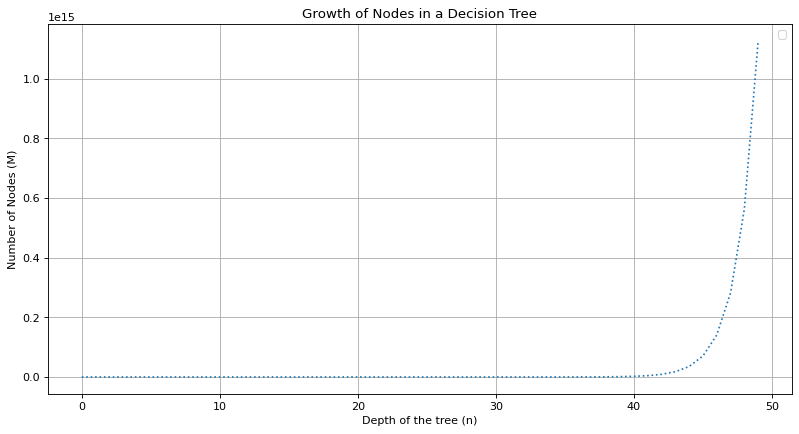

In [2]:
tree_depth = np.arange(0,50)
number_of_nodes = M(tree_depth)


plt.figure(figsize=(12, 6), dpi=80)
plt.plot(tree_depth, number_of_nodes, linestyle=':')
plt.xlabel("Depth of the tree (n)")
plt.ylabel("Number of Nodes (M)")
plt.title("Growth of Nodes in a Decision Tree")
plt.grid(True)
plt.legend()
plt.show()



## 2. Additional Statistics in Fast ODTs

Each node in a Fast ODT maintains statistics required for evaluating and selecting splits based on partial, incrementally observed data.

### 2.1 Feature-Level Statistics

* `Sum_x`: Cumulative sum of observed feature values.
* `last_observed_value`: Most recent value observed for the feature.

### 2.2 Split Candidate Statistics (per potential child node: left and right)

* `2 × sum(y)`: Sum of target values observed on each side.
* `2 × sum(y²)`: Sum of squared target values observed on each side.
* `2 × count`: Number of samples observed on each side.

These statistics are used to compute gain estimates and assess the quality of potential splits.



## 3. Theoretical Memory Footprint per Node

The total theoretical memory cost per node, given `u` features, is expressed as:

```
H(u) = 3 × basic_statistics 
       + u × (2 × basic_feature_statistics 
       + 2 × (3 × statistics_for_potential_split))
```

Where:

* `u` is the number of input features,
* `basic_statistics` includes quantities such as class counts or entropy measures,
* `basic_feature_statistics` refers to per-feature aggregates (e.g., `Sum_x`),
* `statistics_for_potential_split` includes sufficient statistics needed for evaluating split quality (as listed above).

### Equation for FastODTs

In [3]:

def H(u):
    return (3 + u * 8) + 1 # 3 + u * 8 statistics + 1 value

def HM(n,u):
    return H(u).reshape(u.shape[0], 1) * M(n).reshape(1, n.shape[0])

def FODT_bound(n,u):
    return HM(n,u) + 1 + n # 1 sample + n splits

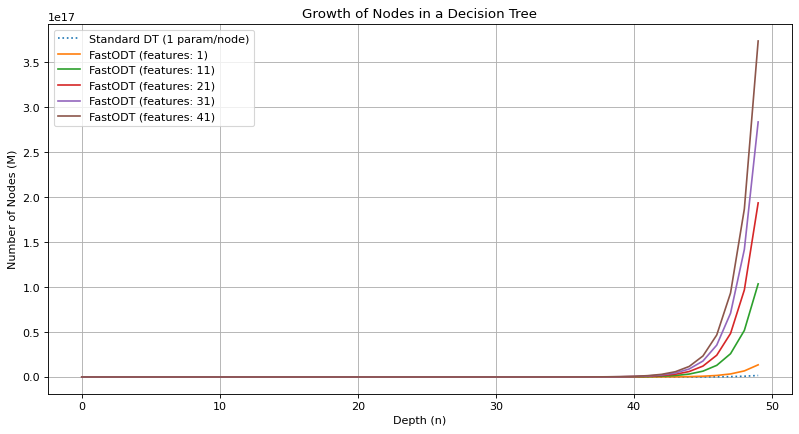

In [4]:


number_of_splits = np.arange(0,50)
number_of_features = np.arange(1,50,10)

plt.figure(figsize=(12, 6), dpi=80)
plt.plot(number_of_splits, DTs_bound(number_of_splits,[0]), linestyle=':', label="Standard DT (1 param/node)")

FODT_bounds = FODT_bound(number_of_splits, number_of_features)
for n, FODT_result in enumerate(FODT_bounds):
    plt.plot(number_of_splits, FODT_result, linestyle='-', label=f"FastODT (features: {number_of_features[n]})")

plt.xlabel("Depth (n)")
plt.ylabel("Number of Nodes (M)")
plt.title("Growth of Nodes in a Decision Tree")
plt.grid(True)
plt.legend()
plt.show()



## 3. Memory bound used in VFDT

Hoeffding trees are bounded by `O(mdvu)` where `m` is number of nodes, `d` is number of stored statistcs, `u` is number of classes/features, `v` is number of values per static. 

In our case it can be similar to the FastODT, with `v = 1`, `d = 8` , `u = number of features` + 3 additional statistics (which could be per feature, but due to being same between all classes can be calculated outside)

if `m = 2**(n + 1) -1` then: `O((3 + u * d * v) * (2**(n + 1) -1))`

Additionally for each node we need to store 1 value + 1 split (except final leaves).


In [5]:

def O(n,d,v,u):
    splits = 1
    value = 1
    return M(n)*(d*v*u + splits + value)  - final_leaves(n) * (splits)

def VFDT_bound(m, d, v, u):
    return O(m,d,v,u)

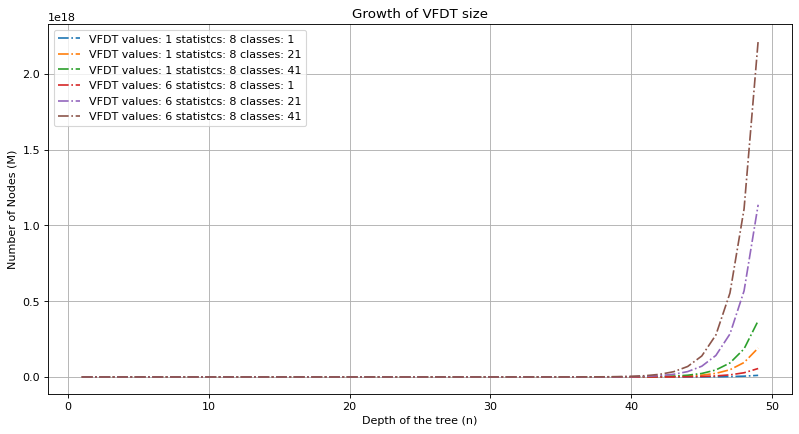

In [6]:
v = np.arange(1,10,5)
d = 8
u = np.arange(1,50,20)
depth = np.arange(1,50)

plt.figure(figsize=(12, 6), dpi=80)
for n_values in v:
    for n_classes in u:
        vfdt_memory_bound = VFDT_bound(depth,d,n_values,n_classes) 
        plt.plot(depth, vfdt_memory_bound, linestyle='-.', label=f"VFDT values: {n_values} statistcs: {d} classes: {n_classes}")

plt.xlabel("Depth of the tree (n)")
plt.ylabel("Number of Nodes (M)")
plt.title("Growth of VFDT size")
plt.grid(True)
plt.legend()
plt.show()

## 4. Training Data Requirements

### 4.1 Standard Decision Trees

Traditional decision trees require access to the **entire training dataset** during the training phase. Consequently, memory usage increases **linearly** with the dataset size.

### 4.2 Fast ODTs

Fast ODTs operate in a **streaming setting** and support **incremental learning**. They process data **one instance at a time** and do not require storage of historical data for further training. This property makes them particularly suitable for large-scale and evolving datasets where retaining the entire dataset is impractical.

### 4.3 VFDDT

Same rules as to Fast ODTs apply to VFDT except VFDT has holds more splits (equal to number of nodes - final leaves),

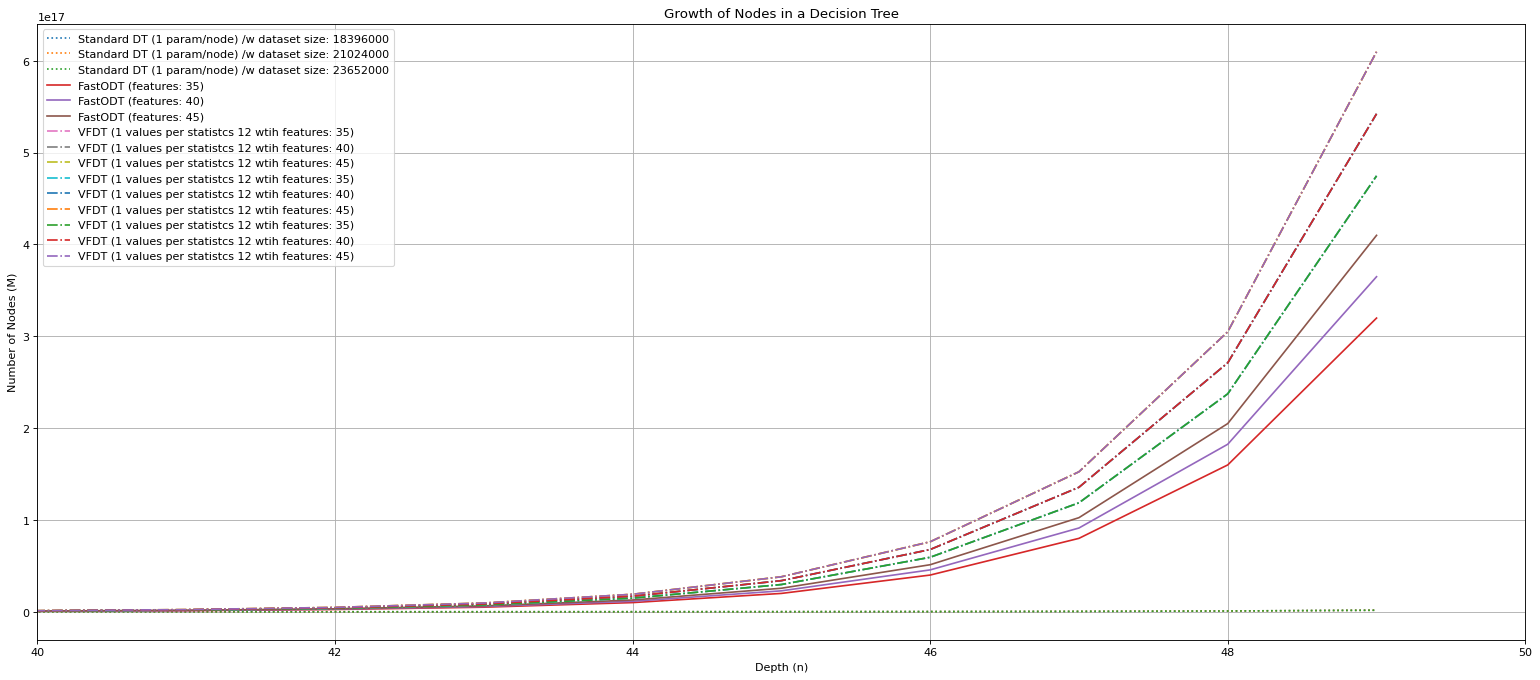

In [7]:

number_of_features = np.arange(35,50,5)
minutes_in_year = 525600
datasets_sizes = minutes_in_year * number_of_features

tree_depth = np.arange(0,50)


plt.figure(figsize=(24, 10), dpi=80)
for dataset_size in datasets_sizes:
    plt.plot(tree_depth,DTs_bound(tree_depth, dataset_size) , linestyle=':', label=f"Standard DT (1 param/node) /w dataset size: {dataset_size}")

FODT_bounds = FODT_bound(tree_depth, number_of_features)
for n, FODT_result in enumerate(FODT_bounds):
    plt.plot(tree_depth, FODT_result, linestyle='-', label=f"FastODT (features: {number_of_features[n]})")

v = np.arange(1,2,1)
d = 12
u = number_of_features 

for dataset_size in datasets_sizes:
    for n_values in v:
        for n_classes in u:
            vfdt_memory_bound = VFDT_bound(tree_depth,d,n_values,n_classes) 
            plt.plot(tree_depth, vfdt_memory_bound, linestyle='-.', label=f"VFDT ({n_values} values per statistcs {d} wtih features: {n_classes})")

plt.xlabel("Depth (n)")
plt.ylabel("Number of Nodes (M)")
plt.title("Growth of Nodes in a Decision Tree")
plt.grid(True)
plt.legend()
plt.xlim(40, 50)   # Cap x-axis between 0 and 3
plt.show()


## Optimized FastODTs and VFDTs

Taking into consideration that after splitting statistics are no more important to store, they can be prune lowering memory bound:

### Equations for Pruned VFDTS and FastODTs

In [8]:
def HM_pruned(n,u):
    value = 1
    return (value + 3 + u.reshape(u.shape[0], 1) * 8) * M(n).reshape(1, n.shape[0])

def FODT_bound_pruned(n, u):
    return HM_pruned(n,u) + 1 + n # 1 sample + n splits

def O_pruned(n,d,v,u): # n is depth
    value = 1
    split = 1
    return final_leaves(n)*(d*v*u + value) + ((M(n) - final_leaves(n)) * (split))

def VFDT_bound_pruned(m, d, v, u):
    return O(m,d,v,u)

# Assuming data observed every 1 second

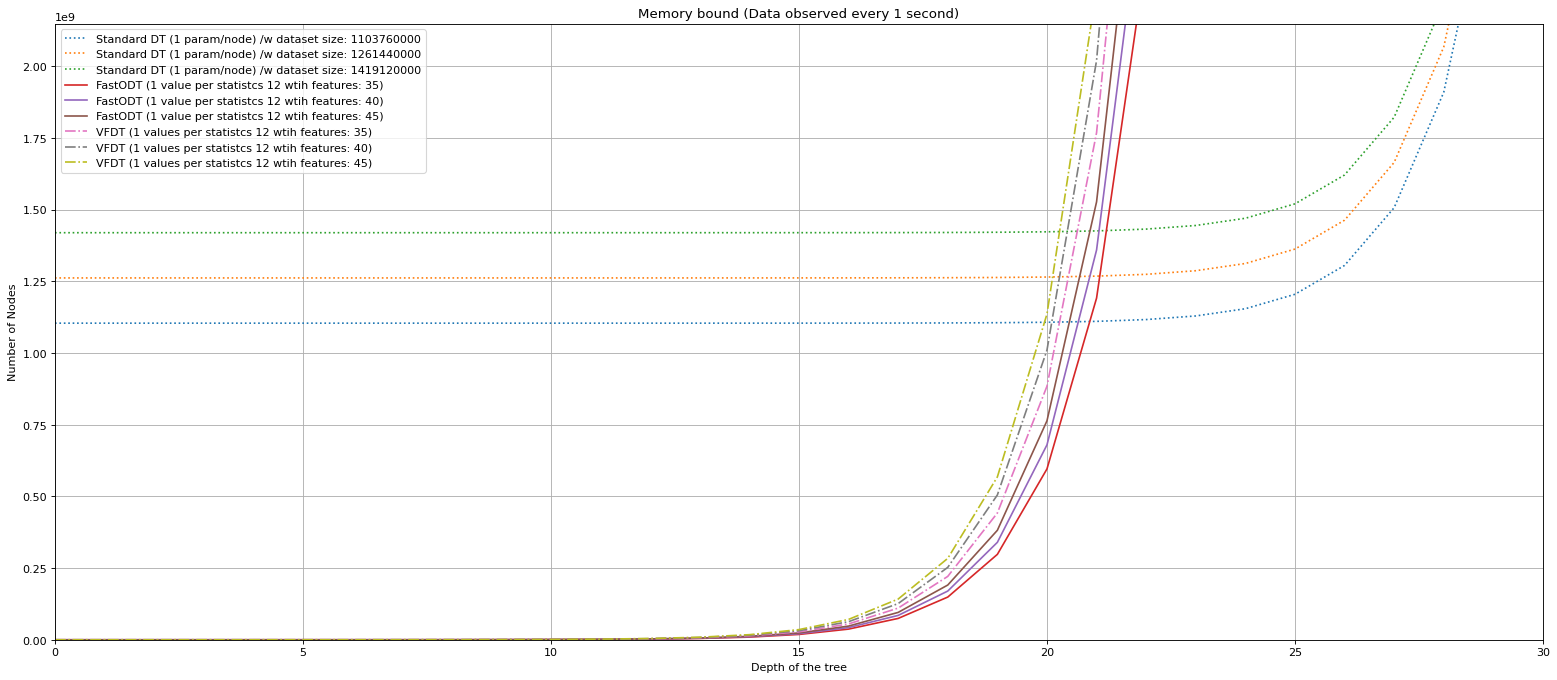

In [9]:

number_of_features = np.arange(35,50,5)
minutes_in_year = 525600 * 60
datasets_sizes = minutes_in_year * number_of_features

tree_depth = np.arange(0,50)


plt.figure(figsize=(24, 10), dpi=80)
for dataset_size in datasets_sizes:
    plt.plot(tree_depth,DTs_bound(tree_depth, dataset_size) , linestyle=':', label=f"Standard DT (1 param/node) /w dataset size: {dataset_size}")

FODT_bounds = FODT_bound_pruned(tree_depth, number_of_features)
for n, FODT_result in enumerate(FODT_bounds):
    plt.plot(tree_depth, FODT_result, linestyle='-', label=f"FastODT (1 value per statistcs 12 wtih features: {number_of_features[n]})")

v = np.arange(1,2,1)
d = 12
u = number_of_features 

for n_values in v:
    for n_feaures in u:
        vfdt_memory_bound = VFDT_bound_pruned(tree_depth,d,n_values,n_feaures) 
        plt.plot(tree_depth, vfdt_memory_bound, linestyle='-.', label=f"VFDT ({n_values} values per statistcs {d} wtih features: {n_feaures})")

plt.xlabel("Depth of the tree")
plt.ylabel("Number of Nodes")
plt.title("Memory bound (Data observed every 1 second)")
plt.grid(True)
plt.legend()
lim = 30
plt.ylim(0, M(lim))
plt.xlim(0, lim)   # Cap x-axis between 0 and 3
plt.show()


# Assuming data observed every 1 minute

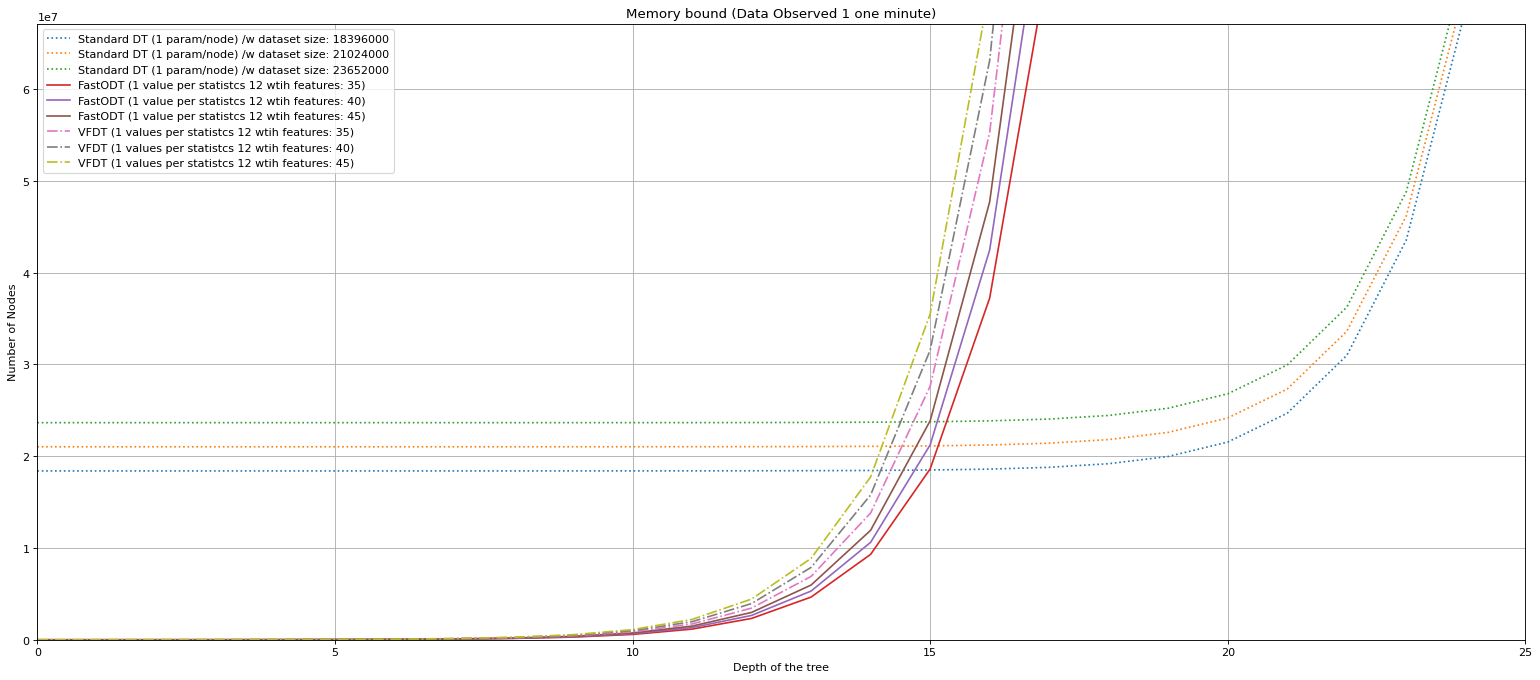

In [10]:

number_of_features = np.arange(35,50,5)
minutes_in_year = 525600
datasets_sizes = minutes_in_year * number_of_features

tree_depth = np.arange(0,50)


plt.figure(figsize=(24, 10), dpi=80)
for dataset_size in datasets_sizes:
    plt.plot(tree_depth,DTs_bound(tree_depth, dataset_size) , linestyle=':', label=f"Standard DT (1 param/node) /w dataset size: {dataset_size}")

FODT_bounds = FODT_bound_pruned(tree_depth, number_of_features)
for n, FODT_result in enumerate(FODT_bounds):
    plt.plot(tree_depth, FODT_result, linestyle='-', label=f"FastODT (1 value per statistcs 12 wtih features: {number_of_features[n]})")

v = np.arange(1,2,1)
d = 12
u = number_of_features 

for n_values in v:
    for n_feaures in u:
        vfdt_memory_bound = VFDT_bound_pruned(tree_depth,d,n_values,n_feaures) 
        plt.plot(tree_depth, vfdt_memory_bound, linestyle='-.', label=f"VFDT ({n_values} values per statistcs {d} wtih features: {n_feaures})")


plt.xlabel("Depth of the tree")
plt.ylabel("Number of Nodes")
plt.title("Memory bound (Data Observed 1 one minute)")
plt.grid(True)
plt.legend()
lim = 25
plt.ylim(0, M(lim))
plt.xlim(0, lim)   # Cap x-axis between 0 and 3
plt.show()


# Assuming data observed every 1 hour

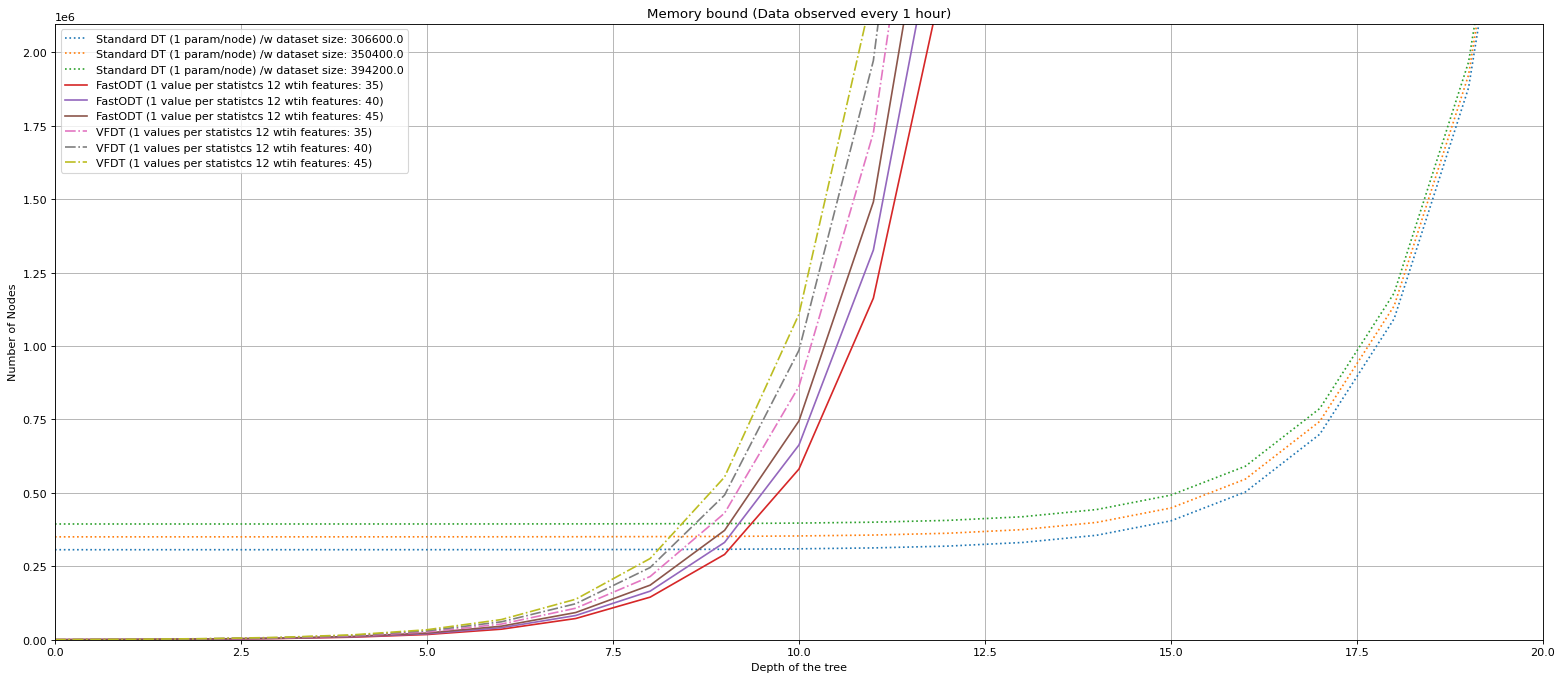

In [11]:

number_of_features = np.arange(35,50,5)
minutes_in_year = 525600/60
datasets_sizes = minutes_in_year * number_of_features

tree_depth = np.arange(0,50)


plt.figure(figsize=(24, 10), dpi=80)
for dataset_size in datasets_sizes:
    plt.plot(tree_depth,DTs_bound(tree_depth, dataset_size) , linestyle=':', label=f"Standard DT (1 param/node) /w dataset size: {dataset_size}")

FODT_bounds = FODT_bound_pruned(tree_depth, number_of_features)
for n, FODT_result in enumerate(FODT_bounds):
    plt.plot(tree_depth, FODT_result, linestyle='-', label=f"FastODT (1 value per statistcs 12 wtih features: {number_of_features[n]})")

v = np.arange(1,2,1)
d = 12
u = number_of_features 

for n_values in v:
    for n_feaures in u:
        vfdt_memory_bound = VFDT_bound_pruned(tree_depth,d,n_values,n_feaures) 
        plt.plot(tree_depth, vfdt_memory_bound, linestyle='-.', label=f"VFDT ({n_values} values per statistcs {d} wtih features: {n_feaures})")


plt.xlabel("Depth of the tree")
plt.ylabel("Number of Nodes")
plt.title("Memory bound (Data observed every 1 hour)")
plt.grid(True)
plt.legend()
lim = 20
plt.ylim(0, M(lim))
plt.xlim(0, lim)   # Cap x-axis between 0 and 3
plt.show()


## Comparing trees used in ensembles

Ensembles usually use multiple trees, but can reuse same dataset stored for them. Hence simplest comparison is how do memory bound scales if multiple trees are reused. 

This can be simply done by multiplying memmory bound of signle tree and adding required training data:

```
EMB = E * tree_memory_bound + dataset
```

### For DTs:

```
EMB = E * tree_memory_bound + dataset
```

### For FastODT and VDFTs

```
EMB = E * tree_memory_bound + 1
```


### Sample every 1 hour

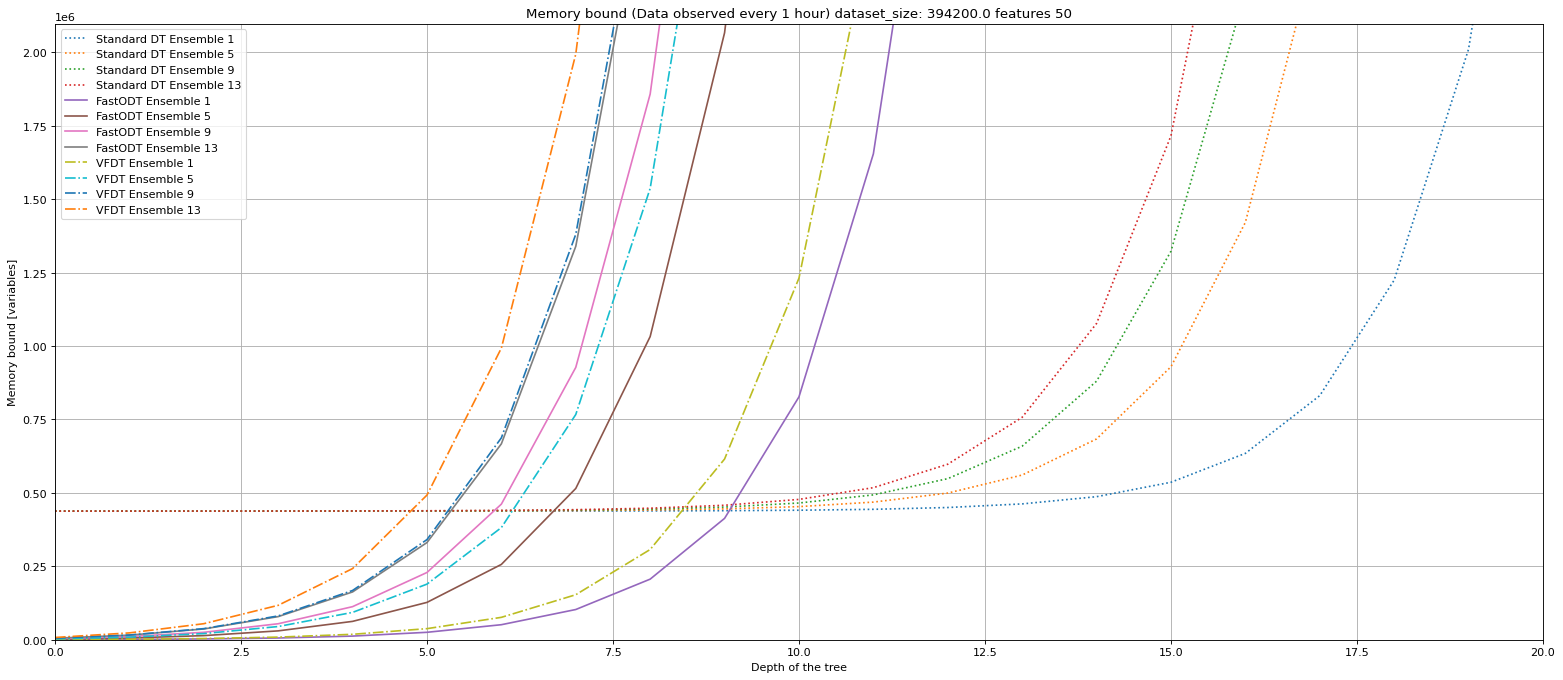

In [31]:
import matplotlib.pyplot as plt
import numpy as np

Ensemble_Size_Sweep = np.arange(1,15,4)

number_of_features = np.array([50])
hours_in_year = 525600/60
datasets_sizes = hours_in_year * number_of_features

tree_depth = np.arange(0,50)


plt.figure(figsize=(24, 10), dpi=80)
for ess in Ensemble_Size_Sweep:
    plt.plot(tree_depth, DTs_bound(tree_depth, datasets_sizes[0], ess) , linestyle=':', label=f"Standard DT Ensemble {ess}")

FODT_bounds = FODT_bound_pruned(tree_depth, number_of_features)
for ess in Ensemble_Size_Sweep:
    for n, FODT_result in enumerate(FODT_bounds):
        plt.plot(tree_depth, ess * FODT_result, linestyle='-', label=f"FastODT Ensemble {ess}")

v = np.arange(1,2,1)
d = 12
u = number_of_features 

for ess in Ensemble_Size_Sweep:
    for n_values in v:
        for n_classes in u:
            vfdt_memory_bound = VFDT_bound_pruned(tree_depth,d,n_values,n_classes) 
            plt.plot(tree_depth, ess * vfdt_memory_bound, linestyle='-.', label=f"VFDT Ensemble {ess}")

plt.xlabel("Depth of the tree")
plt.ylabel("Memory bound [variables]")
plt.title(f"Memory bound (Data observed every 1 hour) dataset_size: {dataset_size} features {number_of_features[0]}")
plt.grid(True)
plt.legend()
lim = 20
plt.ylim(0, M(lim))
plt.xlim(0, lim)   # Cap x-axis between 0 and 3
plt.show()


### Sample every 1 minute

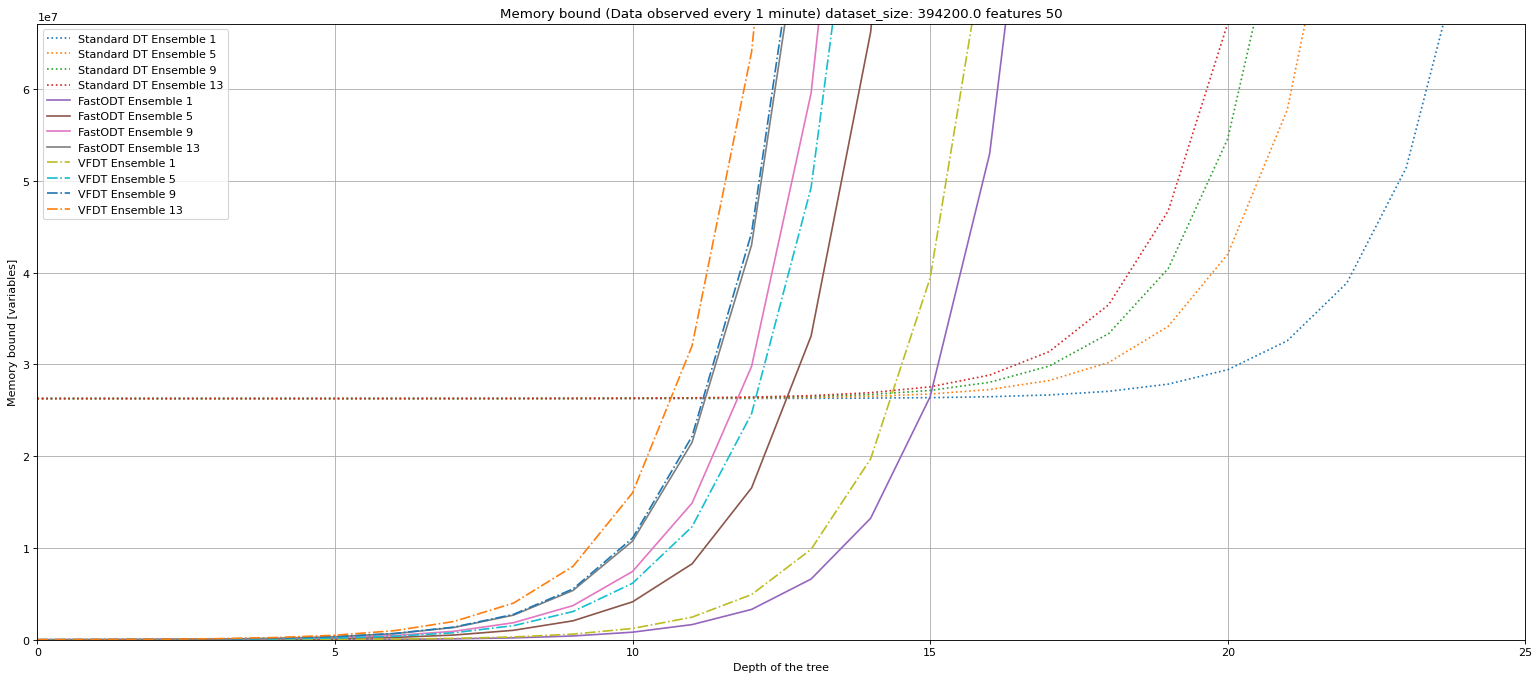

In [32]:
import matplotlib.pyplot as plt
import numpy as np

Ensemble_Size_Sweep = np.arange(1,15,4)

number_of_features = np.array([50])
minutes_in_year = 525600
datasets_sizes = minutes_in_year * number_of_features

tree_depth = np.arange(0,50)


plt.figure(figsize=(24, 10), dpi=80)
for ess in Ensemble_Size_Sweep:
    plt.plot(tree_depth, DTs_bound(tree_depth, datasets_sizes[0], ess) , linestyle=':', label=f"Standard DT Ensemble {ess}")

FODT_bounds = FODT_bound_pruned(tree_depth, number_of_features)
for ess in Ensemble_Size_Sweep:
    for n, FODT_result in enumerate(FODT_bounds):
        plt.plot(tree_depth, ess * FODT_result, linestyle='-', label=f"FastODT Ensemble {ess}")

v = np.arange(1,2,1)
d = 12
u = number_of_features 

for ess in Ensemble_Size_Sweep:
    for n_values in v:
        for n_classes in u:
            vfdt_memory_bound = VFDT_bound_pruned(tree_depth,d,n_values,n_classes) 
            plt.plot(tree_depth, ess * vfdt_memory_bound, linestyle='-.', label=f"VFDT Ensemble {ess}")

plt.xlabel("Depth of the tree")
plt.ylabel("Memory bound [variables]")
plt.title(f"Memory bound (Data observed every 1 minute) dataset_size: {dataset_size} features {number_of_features[0]}")
plt.grid(True)
plt.legend()
lim = 25
plt.ylim(0, M(lim))
plt.xlim(0, lim)   # Cap x-axis between 0 and 3
plt.show()


### Sample every 1 second

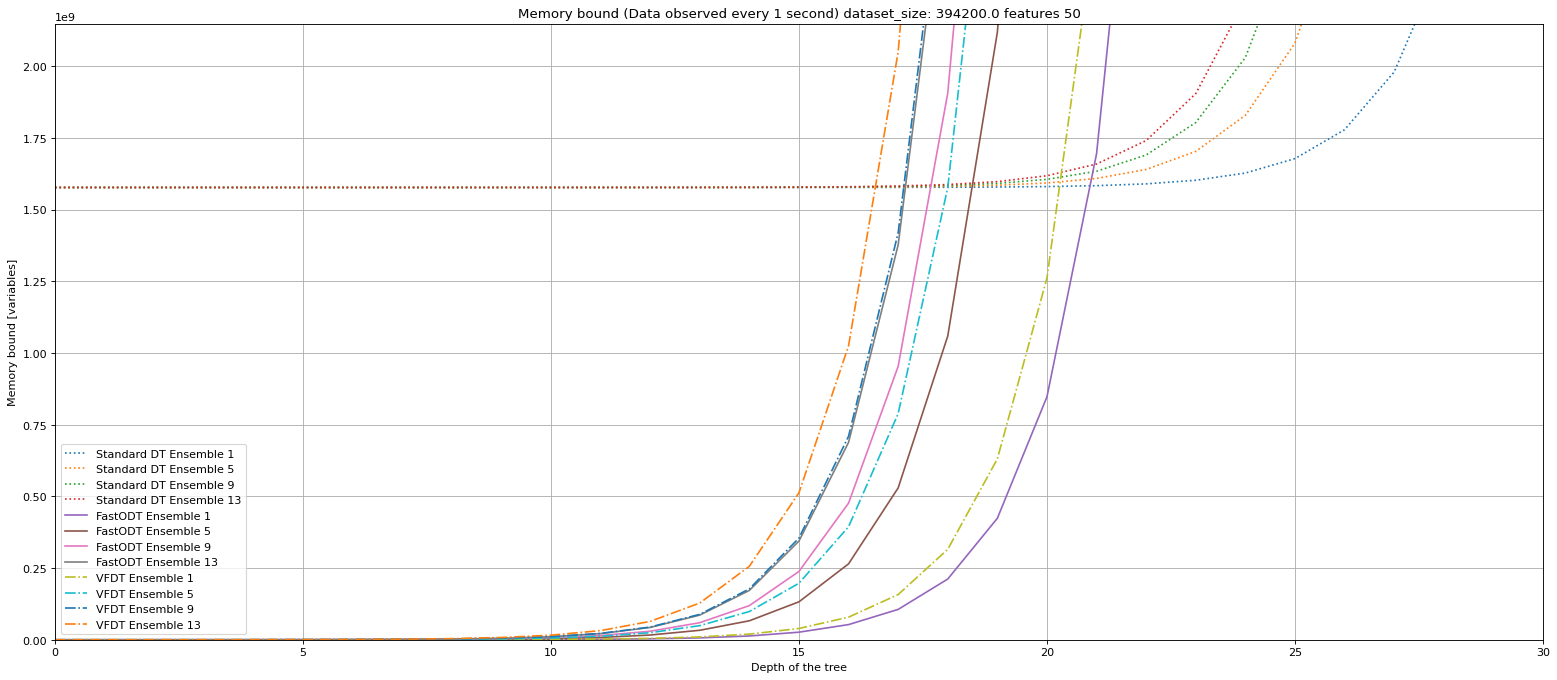

In [33]:
import matplotlib.pyplot as plt
import numpy as np

Ensemble_Size_Sweep = np.arange(1,15,4)

number_of_features = np.array([50])
seconds_in_year = 525600*60
datasets_sizes = seconds_in_year * number_of_features

tree_depth = np.arange(0,50)


plt.figure(figsize=(24, 10), dpi=80)
for ess in Ensemble_Size_Sweep:
    plt.plot(tree_depth, DTs_bound(tree_depth, datasets_sizes[0], ess) , linestyle=':', label=f"Standard DT Ensemble {ess}")

FODT_bounds = FODT_bound_pruned(tree_depth, number_of_features)
for ess in Ensemble_Size_Sweep:
    for n, FODT_result in enumerate(FODT_bounds):
        plt.plot(tree_depth, ess * FODT_result, linestyle='-', label=f"FastODT Ensemble {ess}")

v = np.arange(1,2,1)
d = 12
u = number_of_features 

for ess in Ensemble_Size_Sweep:
    for n_values in v:
        for n_classes in u:
            vfdt_memory_bound = VFDT_bound_pruned(tree_depth,d,n_values,n_classes) 
            plt.plot(tree_depth, ess * vfdt_memory_bound, linestyle='-.', label=f"VFDT Ensemble {ess}")

plt.xlabel("Depth of the tree")
plt.ylabel("Memory bound [variables]")
plt.title(f"Memory bound (Data observed every 1 second) dataset_size: {dataset_size} features {number_of_features[0]}")
plt.grid(True)
plt.legend()
lim = 30
plt.ylim(0, M(lim))
plt.xlim(0, lim)   # Cap x-axis between 0 and 3
plt.show()


## Comment on results

In general FODTs save on splits hence are much better bounded than VFDTs, and even though memory bound of DTs is no match, only VFDT and FODT provide online learning capabilities, being able to learn without storing any data. In real world scenario these bounds rarely will be met as it requires a lot of data with very guassian distribution to let tree initialize all of the nodes.